# Preventing leakage between training and validation

Purging keeps only training observations whose label intervals do not meet any test-label interval:

$$
T_k^{\mathrm{purge}}
=\left\{i\in T_k:
I_i\cap\left(\bigcup_{j\in S_k}I_j\right)=\varnothing\right\}.
$$

Here, $T_k$ is the original training set; $S_k$ is the test set; $I_i$ and $I_j$ are label information intervals. $T_k^{\mathrm{purge}}$ is the retained training set; $k$ indexes folds; $\varnothing$ denotes an empty intersection.

In [1]:
import re as _table_number_re
from IPython.display import HTML as _TableHTML, display as _raw_display


def compact_float_format(number_format=None):
    def format_value(value):
        if number_format is None:
            rendered = str(value)
        elif callable(number_format):
            rendered = str(number_format(value))
        else:
            rendered = number_format % value
        return compact_numeric_token(rendered)
    return format_value


def compact_numeric_token(rendered):
    if not _table_number_re.fullmatch(r"[+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?", rendered):
        return rendered
    value = float(rendered)
    if value != 0.0 and abs(value) < 5e-13:
        return "0"
    if ("." in rendered or "e" in rendered.lower()) and value.is_integer():
        return str(int(value))
    return rendered


def compact_numeric_text(text):
    pattern = r"(?<![0-9.eE])([+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?)(?![0-9.eE])"
    return _table_number_re.sub(pattern, lambda match: compact_numeric_token(match.group(0)), text)


def compact_table_latex(latex):
    return compact_numeric_text(latex)


def _compact_table_html(value):
    frame = value.to_frame() if isinstance(value, pd.Series) else value
    html = frame._repr_html_()
    return '<div style="display:flex;justify-content:center;">' + compact_numeric_text(html) + "</div>"


def display(value):
    if isinstance(value, (pd.DataFrame, pd.Series)):
        return _raw_display(_TableHTML(_compact_table_html(value)))
    return _raw_display(value)

from pathlib import Path
import sys
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm, ListedColormap
import numpy as np
import pandas as pd
from IPython.display import Image
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

ROOT = Path.cwd().parents[1]
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from book_support import ensure_dataset
import hashlib

DATA_URL = "https://data.binance.vision/data/spot/monthly/klines/BTCUSDT/1m/BTCUSDT-1m-2021-01.zip"
DATA_DIR = ROOT / "data" / "public" / "binance"
DATA_PATH = ensure_dataset(ROOT, "binance_btcusdt")
DATA_DIR.mkdir(parents=True, exist_ok=True)
assert DATA_PATH.is_file()
expected_data_hash = "9364A063EFA0604D5B9D2536FB68F922DA5AFA3D8F94A26A527471A1E2F87801"
data_hash = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest().upper()
assert data_hash == expected_data_hash
public_columns = ["Open time", "Open", "High", "Low", "Close", "Volume", "Close time", "Quote volume", "Trades", "Buyer base volume", "Buyer quote volume", "Unused"]
raw = pd.read_csv(DATA_PATH, compression="zip", header=None, names=public_columns, nrows=None)
raw["time"] = pd.to_datetime(raw["Open time"], unit="ms", utc=True).dt.tz_convert(None)
raw = raw.rename(columns={"Close": "close", "Volume": "volume", "Quote volume": "quote_volume", "Trades": "trades"})
raw = raw.sort_values("time").drop_duplicates("time").reset_index(drop=True)

from RiskLabAI.backtest.validation import KFold, PurgedKFold, WalkForward

FIGURES = ROOT / "outputs" / "figures" / "16_temporal_cross_validation"
TABLES = ROOT / "outputs" / "tables" / "16_temporal_cross_validation"
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

minute_data = raw.set_index("time")
bars = pd.DataFrame({
    "Close": minute_data["close"].resample("15min").last(),
    "Volume": minute_data["volume"].resample("15min").sum(),
    "Quote volume": minute_data["quote_volume"].resample("15min").sum(),
    "Trades": minute_data["trades"].resample("15min").sum(),
}).dropna()
log_close = np.log(bars["Close"])
one_bar_return = log_close.diff()
feature_frame = pd.DataFrame({
    "Previous return": one_bar_return.shift(1),
    "One-hour return": log_close.diff(4).shift(1),
    "Past volatility": one_bar_return.shift(1).rolling(16).std(),
    "Log volume change": np.log1p(bars["Volume"]).diff().shift(1),
    "Log quote-volume change": np.log1p(bars["Quote volume"]).diff().shift(1),
    "Log trade-count change": np.log1p(bars["Trades"]).diff().shift(1),
})
label_horizon = 8
forward_return = (log_close.shift(-label_horizon) - log_close).rename("Forward return")
direction = forward_return.gt(0).where(forward_return.notna()).astype("Int64").rename("Direction")
end_time = bars.index.to_series().shift(-label_horizon).rename("End time")
public_frame = pd.concat([feature_frame, direction, forward_return, end_time], axis=1).dropna()
public_x = public_frame[feature_frame.columns].astype(float)
public_y = public_frame["Direction"].astype(int)
event_times = public_frame["End time"]

palette = {"background": "#FFFFFF", "axes": "#FFFFFF", "text": "#1B365D", "cyan": "#0072B2", "amber": "#C76D00", "green": "#00866A", "rose": "#B83B3B", "violet": "#A03A78", "grid": "#D9DEE5", "muted": "#5C6670"}
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11.5, "figure.facecolor": palette["background"], "axes.facecolor": palette["axes"], "axes.edgecolor": palette["text"], "axes.labelcolor": palette["text"], "axes.titlecolor": palette["text"], "xtick.color": palette["text"], "ytick.color": palette["text"], "text.color": palette["text"], "grid.color": palette["grid"], "grid.linestyle": ":", "legend.facecolor": palette["axes"], "legend.edgecolor": palette["grid"], "savefig.facecolor": palette["background"]})

def save_table(frame, stem, caption, label, float_format="%.6f", fit=True):
    frame.to_csv(TABLES / f"{stem}.csv", index=False)
    latex = compact_table_latex(frame.to_latex(index=False, escape=True, float_format=compact_float_format(float_format), caption=caption, label=label, position="H"))
    if fit:
        latex = latex.replace(r"\begin{tabular}", r"\begin{adjustbox}{max width=\textwidth}\begin{tabular}", 1).replace(r"\end{tabular}", r"\end{tabular}\end{adjustbox}", 1)
    else:
        latex = latex.replace(r"\begin{tabular}", "\\centering\n" + r"\begin{tabular}", 1)
    (TABLES / f"{stem}.tex").write_text(latex, encoding="utf-8")

def overlap_count(train_indices, test_indices, times):
    allowed = PurgedKFold.filtered_training_indices_with_embargo(times, times.iloc[test_indices], embargo_fraction=0, continous_test_times=False)
    allowed_positions = set(times.index.get_indexer(allowed.index).tolist())
    return sum(int(int(index) not in allowed_positions) for index in train_indices)

def score_splits(name, splits):
    predictions = np.full(len(public_x), np.nan)
    records = []
    for fold, (train_indices, test_indices) in enumerate(splits, start=1):
        if len(train_indices) == 0 or public_y.iloc[train_indices].nunique() < 2:
            records.append({"Method": name, "Fold": fold, "Training observations": len(train_indices), "Test observations": len(test_indices), "Accuracy": np.nan})
            continue
        estimator = LogisticRegression(max_iter=1000, solver="lbfgs")
        estimator.fit(public_x.iloc[train_indices], public_y.iloc[train_indices])
        fold_predictions = estimator.predict(public_x.iloc[test_indices])
        predictions[test_indices] = fold_predictions
        records.append({"Method": name, "Fold": fold, "Training observations": len(train_indices), "Test observations": len(test_indices), "Accuracy": accuracy_score(public_y.iloc[test_indices], fold_predictions)})
    return pd.DataFrame(records), predictions

def split_matrix(split_sets, length):
    matrix = np.zeros((len(split_sets), length), dtype=int)
    for row, (train_indices, test_indices) in enumerate(split_sets):
        matrix[row, train_indices] = 1
        matrix[row, test_indices] = 2
    return matrix

split_colors = ListedColormap([palette["muted"], palette["cyan"], palette["rose"], palette["amber"], palette["violet"]])
split_norm = BoundaryNorm(np.arange(-0.5, 5.5, 1), split_colors.N)
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11.5, "figure.facecolor": "#FFFFFF", "axes.facecolor": "#FFFFFF", "axes.edgecolor": "#5C6670", "axes.labelcolor": "#1B365D", "axes.titlecolor": "#1B365D", "axes.titleweight": "bold", "xtick.color": "#5C6670", "ytick.color": "#5C6670", "text.color": "#1B365D", "grid.color": "#D9DEE5", "grid.linestyle": ":", "grid.linewidth": 0.8, "legend.facecolor": "#FFFFFF", "legend.edgecolor": "#D9DEE5", "legend.framealpha": 0.96, "savefig.facecolor": "#FFFFFF", "savefig.transparent": False, "savefig.dpi": 300, "pdf.fonttype": 42, "ps.fonttype": 42})
import RiskLabAI as _risklabai_release
assert _risklabai_release.__version__ == "3.2.0"


## Purged Fold Anatomy

,Fold,Original training observations,Removed by overlap,Removed by embargo,Final training observations,Test observations
0,1,2459,8,29,2422,492
1,2,2459,16,29,2414,492
2,3,2459,16,29,2414,492
3,4,2459,16,29,2414,492
4,5,2459,16,29,2414,492
5,6,2460,8,0,2452,491


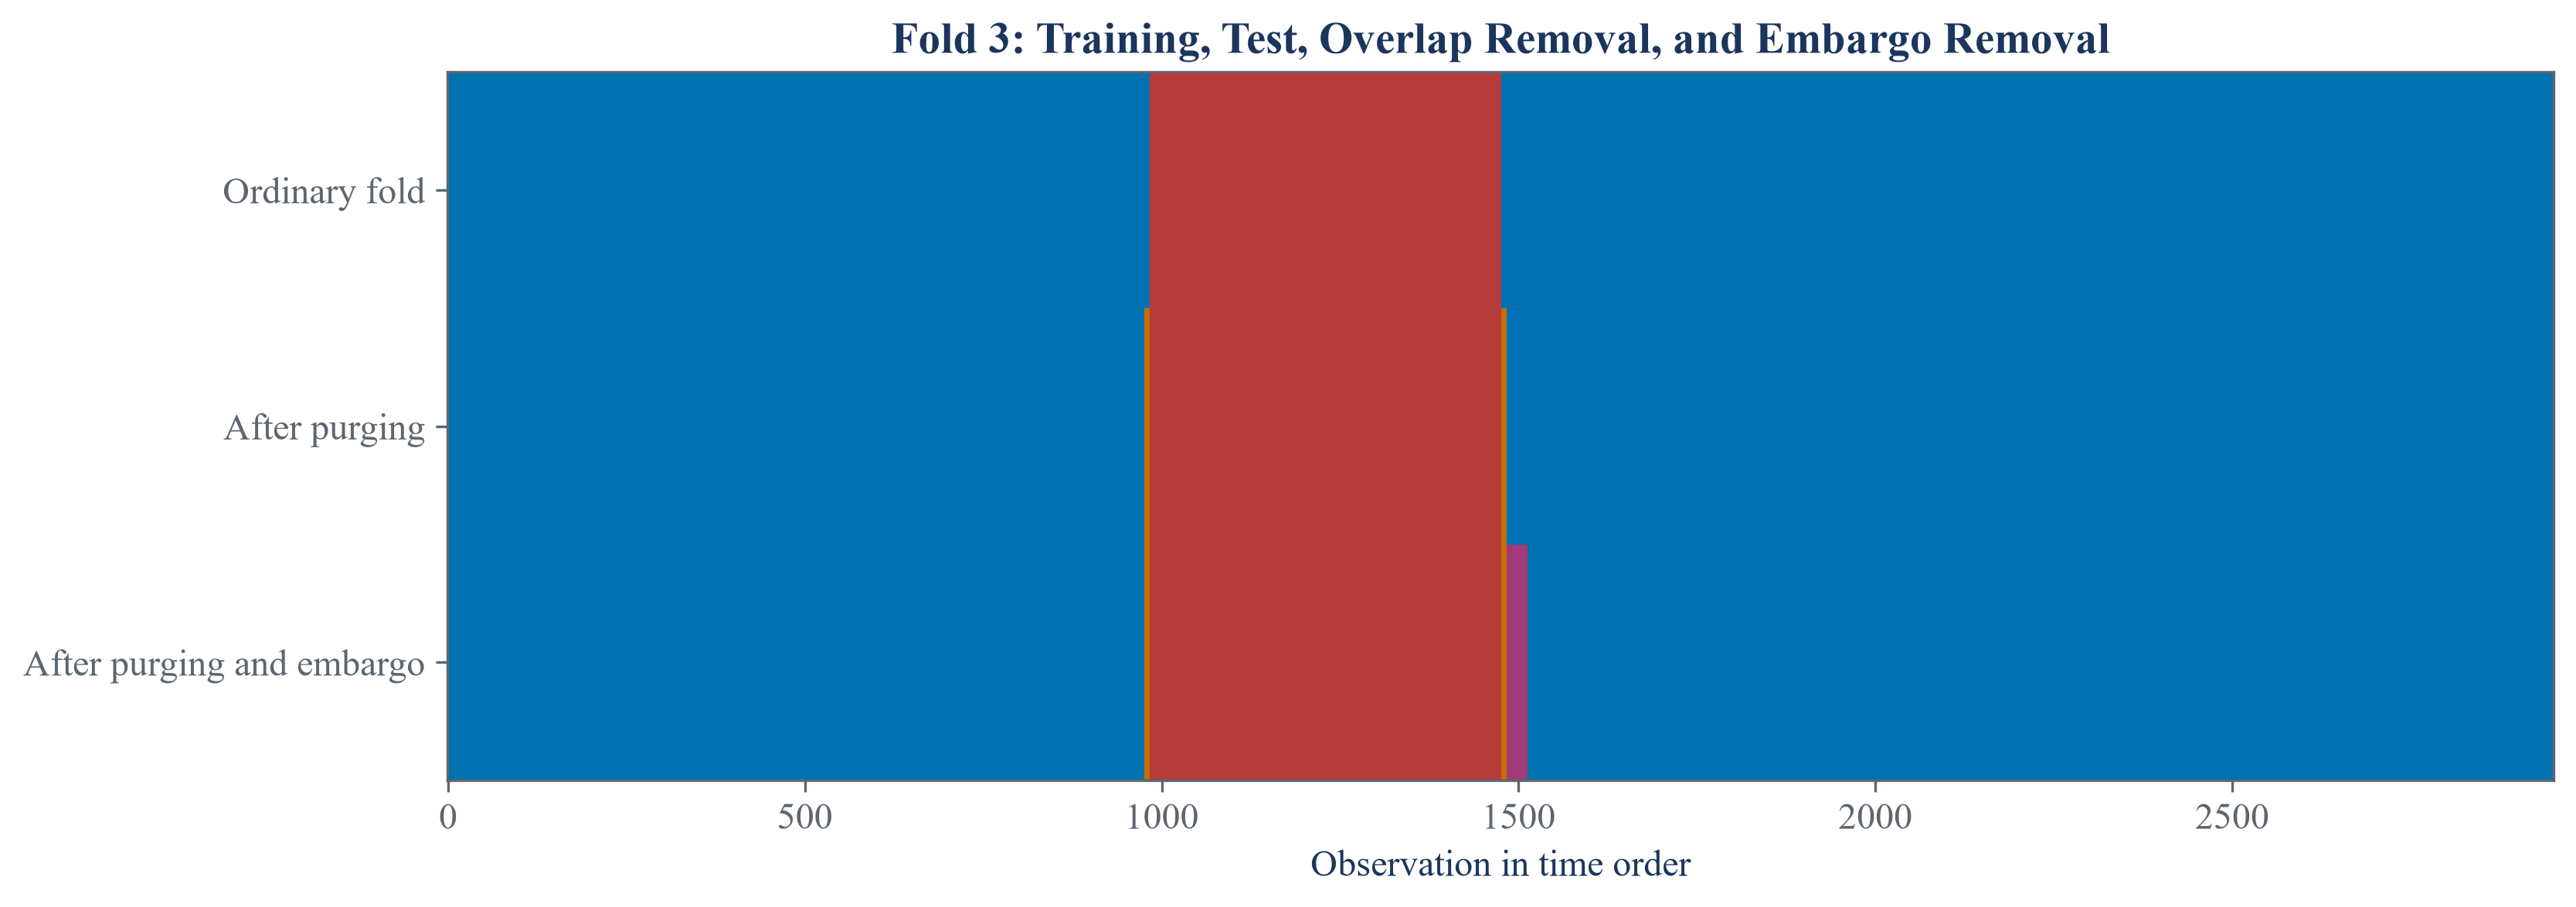

In [2]:
n_splits = 6
ordinary_splits = list(KFold(n_splits=n_splits, shuffle=False).split(public_x, public_y))
no_embargo_splits = list(PurgedKFold(n_splits=n_splits, times=event_times, embargo=0).split(public_x, public_y))
embargo_fraction = 0.01
embargo_splits = list(PurgedKFold(n_splits=n_splits, times=event_times, embargo=embargo_fraction).split(public_x, public_y))
fold_size_records = []
for fold, ((ordinary_train, test_indices), (purged_train, _), (embargo_train, _)) in enumerate(zip(ordinary_splits, no_embargo_splits, embargo_splits), start=1):
    ordinary_set = set(ordinary_train.tolist())
    purged_set = set(purged_train.tolist())
    embargo_set = set(embargo_train.tolist())
    fold_size_records.append({
        "Fold": fold,
        "Original training observations": len(ordinary_set),
        "Removed by overlap": len(ordinary_set - purged_set),
        "Removed by embargo": len(purged_set - embargo_set),
        "Final training observations": len(embargo_set),
        "Test observations": len(test_indices),
    })
purging_fold_sizes = pd.DataFrame(fold_size_records)
save_table(purging_fold_sizes, "purging_fold_sizes", "Training observations removed by label overlap and a one-percent embargo.", "tab:chapter14-purging-fold-sizes", fit=True)
display(purging_fold_sizes)

selected_fold = 3
ordinary_train, test_indices = ordinary_splits[selected_fold - 1]
purged_train, _ = no_embargo_splits[selected_fold - 1]
embargo_train, _ = embargo_splits[selected_fold - 1]
anatomy = np.zeros((3, len(public_x)), dtype=int)
anatomy[0, ordinary_train] = 1
anatomy[0, test_indices] = 2
anatomy[1, ordinary_train] = 3
anatomy[1, purged_train] = 1
anatomy[1, test_indices] = 2
anatomy[2, ordinary_train] = 3
anatomy[2, purged_train] = 4
anatomy[2, embargo_train] = 1
anatomy[2, test_indices] = 2
figure, axis = plt.subplots(figsize=(11.0, 3.8), constrained_layout=True)
axis.imshow(anatomy, aspect="auto", interpolation="nearest", cmap=split_colors, norm=split_norm)
axis.set_yticks([0, 1, 2])
axis.set_yticklabels(["Ordinary fold", "After purging", "After purging and embargo"])
axis.set_xlabel("Observation in time order")
axis.set_title("Fold 3: Training, Test, Overlap Removal, and Embargo Removal")
figure.savefig(FIGURES / "purging_embargo_anatomy.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "purging_embargo_anatomy.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "purging_embargo_anatomy.png")))
plt.close(figure)

The embargo adds a declared number of observations after the test information ends before later training observations may be kept:

$$
m=\lfloor \varepsilon n\rfloor,
\qquad
\widetilde I(S_k;\varepsilon)
=\left[\min_{j\in S_k}s_j,\ e_{q_k+m}\right].
$$

Here, $\varepsilon$ is the embargo fraction; $n$ is the sample size; $m$ is the embargo length rounded down. $S_k$ is test fold $k$; $s_j$ is a label start; $q_k$ locates the last test-information end; $e_{q_k+m}$ is the extended end; $\widetilde I$ is the protected interval.

## Testing leakage control across horizon and embargo choices

,Label horizon in bars,Embargo fraction,Mean removed observations,Largest removed share
0,1,0,1.666667,0.000822
1,1,0.005,13.333333,0.006579
2,1,0.010,25.833333,0.012747
3,1,0.020,50,0.024671
4,4,0,6.666667,0.003289
5,4,0.005,18.333333,0.009046
6,4,0.010,30.833333,0.015214
7,4,0.020,55,0.027138
8,8,0,13.333333,0.006579
9,8,0.005,25,0.012336


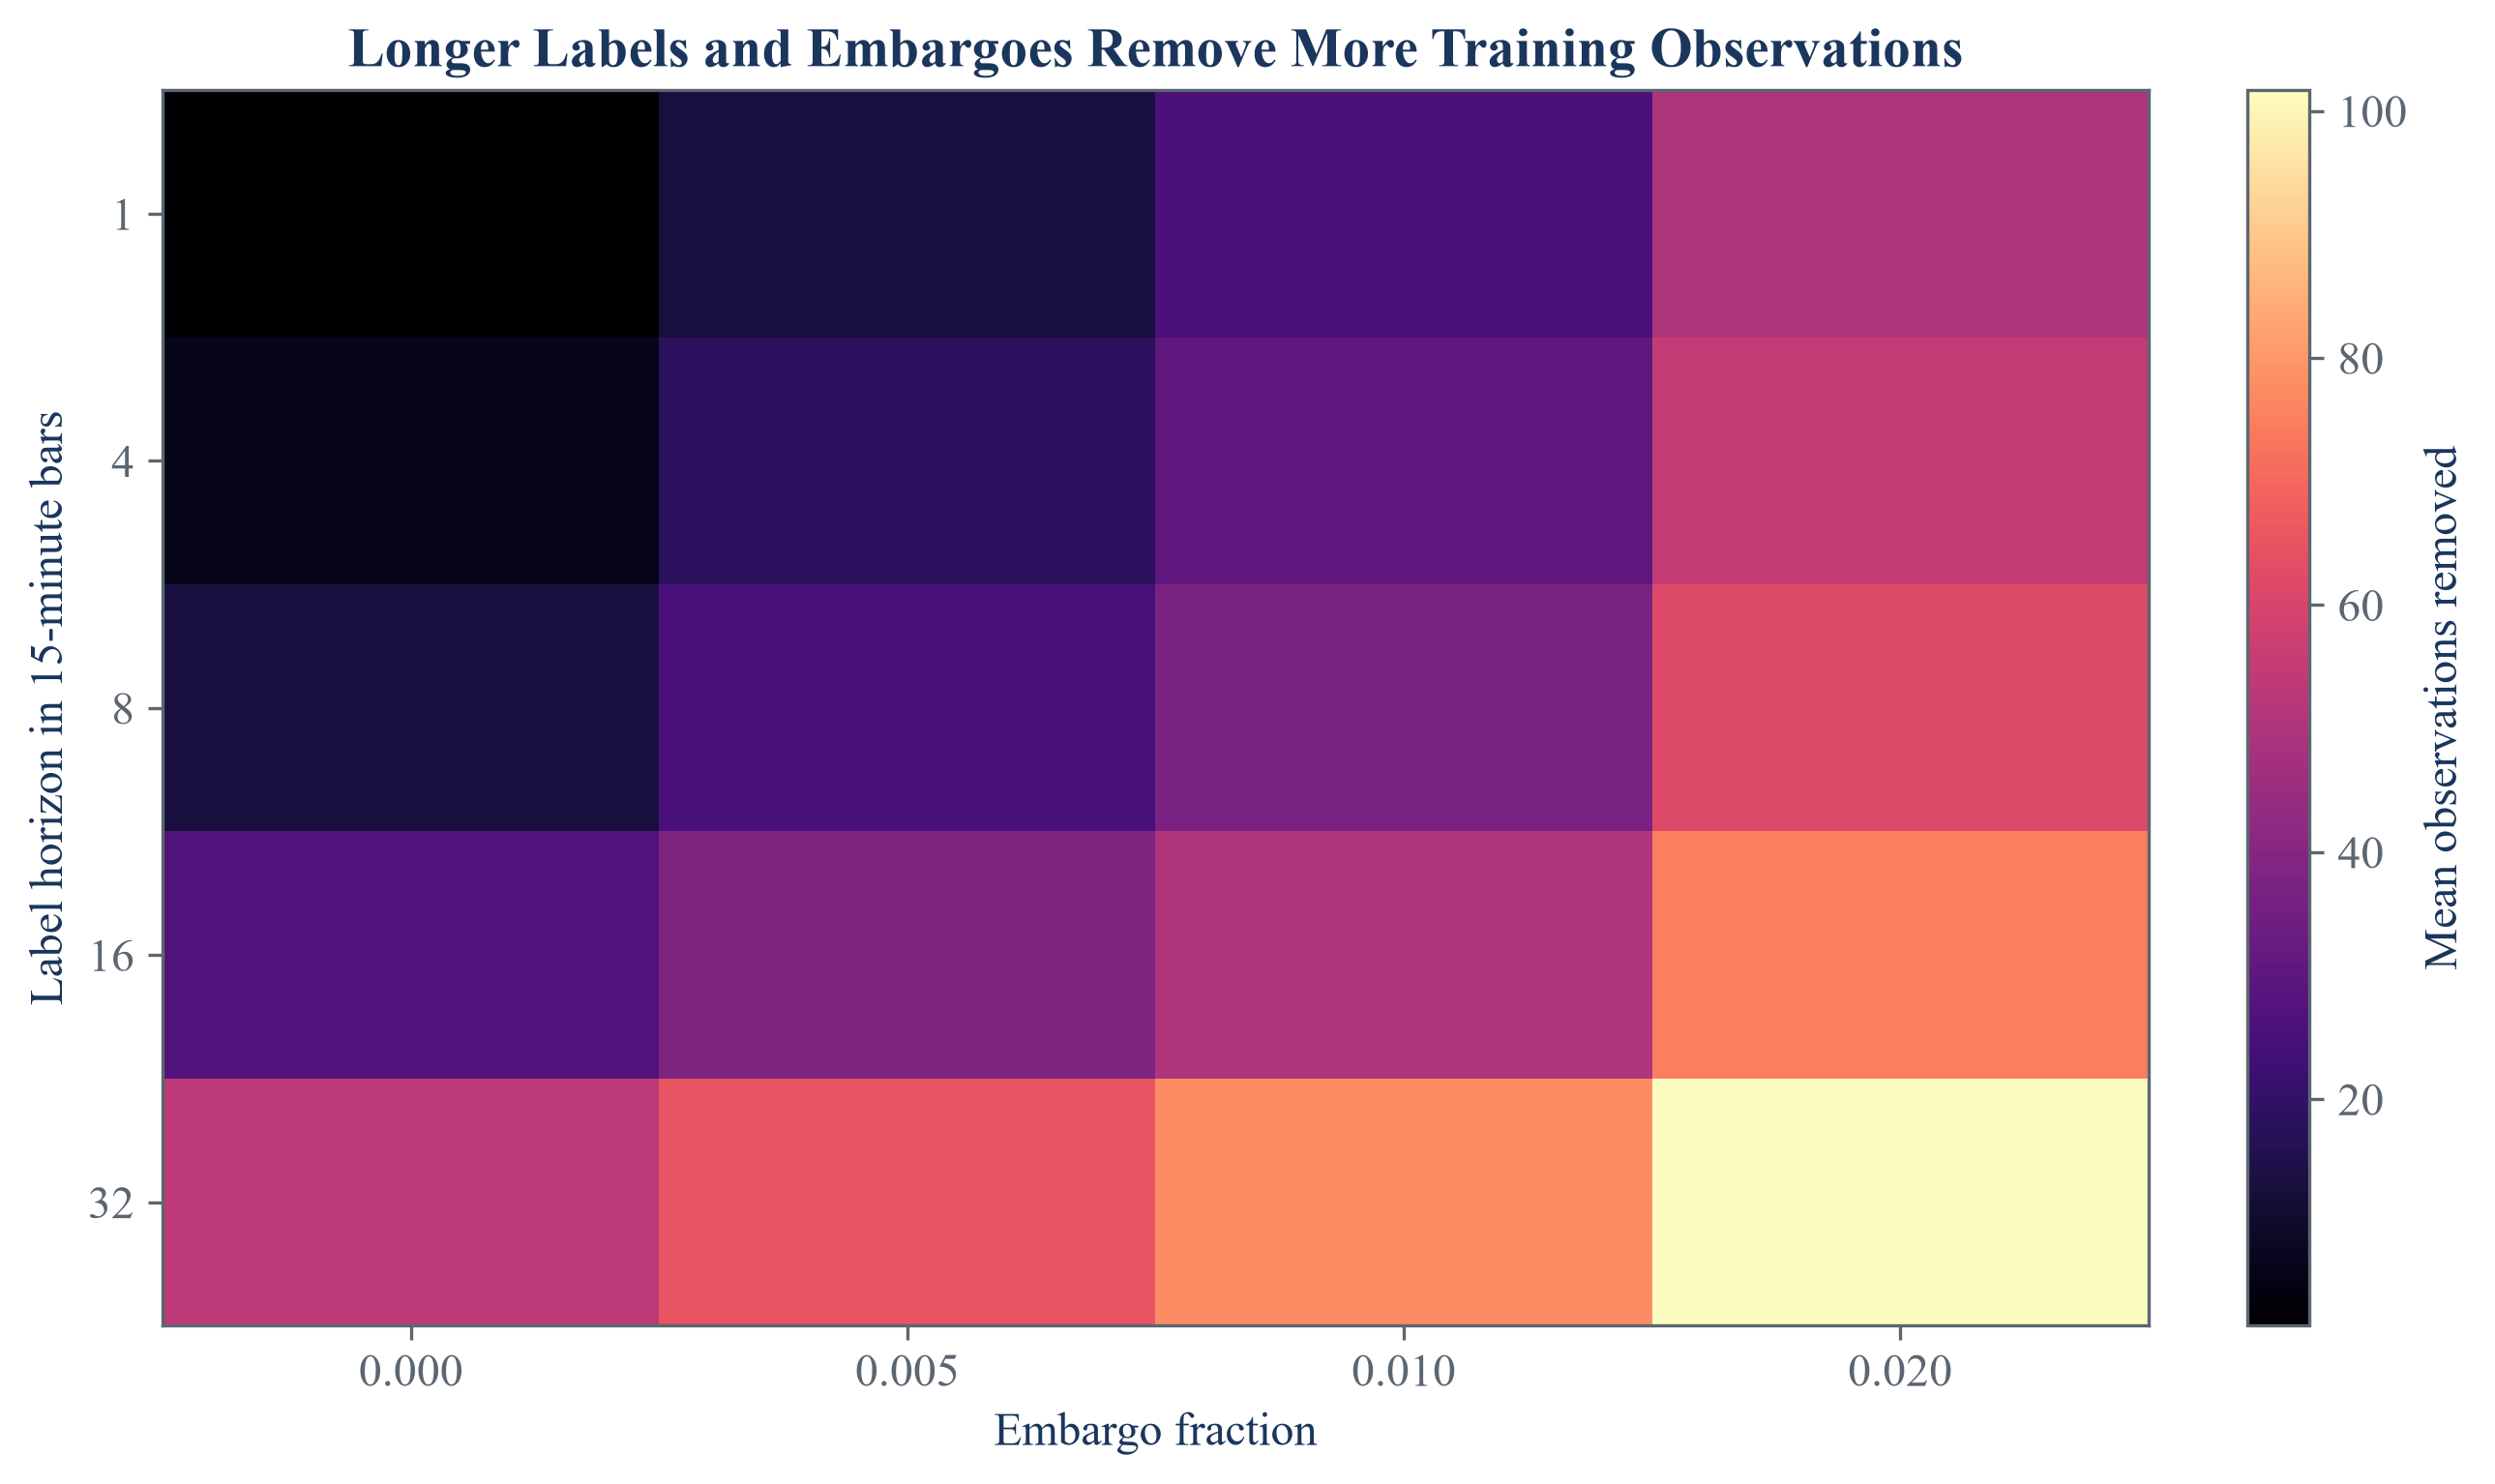

In [3]:
common_length = len(public_x) - 32
common_x = public_x.iloc[:common_length]
sensitivity_records = []
for horizon in [1, 4, 8, 16, 32]:
    ends = pd.Series(public_x.index[np.arange(common_length) + horizon], index=common_x.index)
    ordinary = list(KFold(n_splits=n_splits, shuffle=False).split(common_x))
    for embargo in [0.0, 0.005, 0.01, 0.02]:
        current = list(PurgedKFold(n_splits=n_splits, times=ends, embargo=embargo).split(common_x))
        removals = [len(base_train) - len(clean_train) for (base_train, _), (clean_train, _) in zip(ordinary, current)]
        sensitivity_records.append({
            "Label horizon in bars": horizon,
            "Embargo fraction": embargo,
            "Mean removed observations": float(np.mean(removals)),
            "Largest removed share": float(max(removals) / len(ordinary[0][0])),
        })
horizon_embargo_sensitivity = pd.DataFrame(sensitivity_records)
save_table(horizon_embargo_sensitivity, "horizon_embargo_sensitivity", "Sensitivity of training-set removal to label horizon and embargo fraction.", "tab:chapter14-horizon-embargo-sensitivity", fit=True)
display(horizon_embargo_sensitivity.round(6))

heatmap = horizon_embargo_sensitivity.pivot(index="Label horizon in bars", columns="Embargo fraction", values="Mean removed observations")
figure, axis = plt.subplots(figsize=(8.5, 5.0), constrained_layout=True)
image = axis.imshow(heatmap.to_numpy(), aspect="auto", cmap="magma")
axis.set_xticks(np.arange(len(heatmap.columns)))
axis.set_xticklabels([f"{value:.3f}" for value in heatmap.columns])
axis.set_yticks(np.arange(len(heatmap.index)))
axis.set_yticklabels(heatmap.index)
axis.set_xlabel("Embargo fraction")
axis.set_ylabel("Label horizon in 15-minute bars")
axis.set_title("Longer Labels and Embargoes Remove More Training Observations")
figure.colorbar(image, ax=axis, label="Mean observations removed")
figure.savefig(FIGURES / "horizon_embargo_sensitivity.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "horizon_embargo_sensitivity.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "horizon_embargo_sensitivity.png")))
plt.close(figure)

Every stored prediction comes from the fit whose training set excludes and protects the fold containing that observation:

$$
\widehat y_i
=\widehat f^{(-k(i))}(x_i),
\qquad i\in S_{k(i)}.
$$

Here, $i$ indexes observations; $k(i)$ is the fold containing $i$; $S_{k(i)}$ is that test fold. $x_i$ is the feature vector; $\widehat f^{(-k(i))}$ is the fold-specific fitted rule; $\widehat y_i$ is the held-out prediction.

## Comparing manual predictions with library output

In [4]:
validator = PurgedKFold(n_splits=n_splits, times=event_times, embargo=embargo_fraction)
estimator = LogisticRegression(max_iter=1000, solver="lbfgs")
manual_predictions = np.full(len(public_x), np.nan)
for train_indices, test_indices in validator.split(public_x, public_y):
    fitted = clone(estimator)
    fitted.fit(public_x.iloc[train_indices], public_y.iloc[train_indices])
    manual_predictions[test_indices] = fitted.predict(public_x.iloc[test_indices])
collected_predictions = validator.backtest_predictions(estimator, public_x, public_y, n_jobs=1)["Path 1"]
path_records = []
for fold, item in enumerate(validator.backtest_paths(public_x)["Path 1"], start=1):
    train_indices = item["Train"]
    test_indices = item["Test"]
    path_records.append({
        "Fold": fold,
        "Training observations": len(train_indices),
        "Test observations": len(test_indices),
        "First training time": str(public_x.index[train_indices[0]]),
        "Last training time": str(public_x.index[train_indices[-1]]),
        "First test time": str(public_x.index[test_indices[0]]),
        "Last test time": str(public_x.index[test_indices[-1]]),
    })
purged_path_summary = pd.DataFrame(path_records)
save_table(purged_path_summary, "purged_path_summary", "Time ranges and sizes for the six purged public-data folds.", "tab:chapter14-purged-path-summary", fit=True)
display(purged_path_summary)

prediction_check = pd.DataFrame({
    "Calculation": ["Manual fold loop", "Collected fold predictions"],
    "Predictions": [int(np.isfinite(manual_predictions).sum()), int(np.isfinite(collected_predictions).sum())],
    "Accuracy": [accuracy_score(public_y, manual_predictions), accuracy_score(public_y, collected_predictions)],
    "Agreement with manual calculation": [1.0, float(np.mean(collected_predictions == manual_predictions))],
})
save_table(prediction_check, "prediction_equivalence", "Independent and collected purged-fold predictions on the public data.", "tab:chapter14-prediction-equivalence", fit=True)
display(prediction_check.round(6))

,Fold,Training observations,Test observations,First training time,Last training time,First test time,Last test time
0,1,2422,492,2021-01-06 16:30:00,2021-01-31 21:45:00,2021-01-01 04:15:00,2021-01-06 07:00:00
1,2,2414,492,2021-01-01 04:15:00,2021-01-31 21:45:00,2021-01-06 07:15:00,2021-01-11 10:00:00
2,3,2414,492,2021-01-01 04:15:00,2021-01-31 21:45:00,2021-01-11 10:15:00,2021-01-16 13:00:00
3,4,2414,492,2021-01-01 04:15:00,2021-01-31 21:45:00,2021-01-16 13:15:00,2021-01-21 16:00:00
4,5,2414,492,2021-01-01 04:15:00,2021-01-31 21:45:00,2021-01-21 16:15:00,2021-01-26 19:00:00
5,6,2452,491,2021-01-01 04:15:00,2021-01-26 17:00:00,2021-01-26 19:15:00,2021-01-31 21:45:00


,Calculation,Predictions,Accuracy,Agreement with manual calculation
0,Manual fold loop,2951,0.489326,1
1,Collected fold predictions,2951,0.489326,1


## Tests

In [5]:
assert data_hash == "9364A063EFA0604D5B9D2536FB68F922DA5AFA3D8F94A26A527471A1E2F87801"
assert purging_fold_sizes.shape == (6, 6)
assert (purging_fold_sizes["Removed by overlap"] > 0).all()
assert (purging_fold_sizes["Removed by embargo"] >= 0).all()
assert (purging_fold_sizes["Final training observations"] < purging_fold_sizes["Original training observations"]).all()
assert horizon_embargo_sensitivity.shape == (20, 4)
assert horizon_embargo_sensitivity["Mean removed observations"].ge(0).all()
assert horizon_embargo_sensitivity.groupby("Embargo fraction")["Mean removed observations"].mean().is_monotonic_increasing
assert horizon_embargo_sensitivity.groupby("Label horizon in bars")["Mean removed observations"].mean().is_monotonic_increasing
assert np.array_equal(manual_predictions, collected_predictions)
assert prediction_check["Accuracy"].between(0, 1).all()
assert purged_path_summary.shape == (6, 7)
assert (FIGURES / "purging_embargo_anatomy.pdf").is_file()
assert (FIGURES / "horizon_embargo_sensitivity.pdf").is_file()
assert (TABLES / "purging_fold_sizes.tex").is_file()
assert (TABLES / "horizon_embargo_sensitivity.tex").is_file()
assert (TABLES / "purged_path_summary.tex").is_file()
assert (TABLES / "prediction_equivalence.tex").is_file()